# Ⅰ第4回 演習3 保存したモデルを別のファイルで使う

**問い**：演習1 で保存した CNN は，学習に使っていない **新しい写真** を見分けられるか．既存の LLM ならどうか．

第2回の「学習済みの重みを読む」と同じ 5 つの手順（読む → 組み立てる → 重みを入れる → 評価モード → 推論）を，自分のモデルで行う．
このノートブックでは学習しない（optimizer・`loss.backward()` は使わない）．

## (0) 番号の設定

In [1]:
# ===== (0) 番号の設定 =====
MEMBER_NO = 3                 # ← グループ内の自分の番号 (1〜5)．presenter はこの番号の順に演習ごとに交代する

# 授業用フォルダ（AI_TD）のルートを import パスに追加する（ノートブックをどこから開いても動く）
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".dlcourse_root").exists())
sys.path.insert(0, str(ROOT))
print("作業フォルダ:", ROOT)

作業フォルダ: /Users/itagakisogo/AI_TD


## (1) 新しい写真を用意する（10 分）

1. 演習1 と同じ 2 つのクラスを，**各 5 枚** 新しく撮る（学習に使った写真は使わない．撮る場所や背景を変えてもよい）
2. `assets/mynew_photos/<クラス名>/` に入れる（フォルダ名は `assets/myphotos/` と同じにする）
3. ターミナルで `python setup/prepare_mydata.py --new` を実行する（`assets/mynew/` にそろう）

ケーブル画像で進めた人は，そのまま次へ（ケーブル画像から 10 枚を使う．学習に使った写真が混ざる）．

## (2) 手順 1：重みのファイルを読む

In [2]:
import torch
import torch.nn as nn
from torchvision import transforms
from torchvision.datasets import ImageFolder
import pandas as pd
import matplotlib.pyplot as plt
from common.device import get_device
from common.todo import checkpoint
plt.rcParams["font.family"] = ["Hiragino Sans", "sans-serif"]   # Mac の日本語フォント（文字化け防止）

device = get_device()
ckpt = torch.load(ROOT / "results" / "my_cnn.pt", map_location=device)   # 演習1 の最後で保存したファイル
class_names = ckpt["classes"]
size = ckpt["image_size"]
print("入っているもの:", list(ckpt))
print("クラス:", class_names, "| 画像の大きさ:", size, "| 演習1 のテスト正解率:", f"{ckpt['test_accuracy'] * 100:.1f}%")
c, h, w = 3, size, size    # ⑦で使う名前を，保存した値から作る

入っているもの: ['state_dict', 'classes', 'image_size', 'test_accuracy']
クラス: ['away', 'home'] | 画像の大きさ: 64 | 演習1 のテスト正解率: 100.0%


## (3) 手順 2：同じ構造を組み立てる

演習1 の **⑦（CNN）のセルをコピーして** 下に貼る．`len(full_dataset.classes)` は `len(class_names)` に直す（このファイルには `full_dataset` が無い）．

In [4]:
# 入力画像のチャネル数・高さ・幅
INPUT_CHANNELS = c
IMAGE_HEIGHT = h
IMAGE_WIDTH = w

# 畳み込み層が出す特徴マップの枚数
CONV1_OUT_CHANNELS = 16

# 3×3 のフィルタで画像をなぞる．PADDING で縁を補い，POOL_SIZE で縦横を半分にする
KERNEL_SIZE = 3
PADDING = 1
POOL_SIZE = 2

POOL_NUM = 1

FC1_OUT_CHANNELS = 128

# 出力の数 = 分類するクラスの数
OUTPUT_SIZE = len(class_names)

# プーリング後の高さと幅（64 → 32）
OUT_HEIGHT = IMAGE_HEIGHT // (POOL_SIZE ** POOL_NUM)
OUT_WIDTH = IMAGE_WIDTH // (POOL_SIZE ** POOL_NUM)

# 全結合層に渡す長さ = 特徴マップの枚数 × 高さ × 幅
FLATTEN_SIZE = CONV1_OUT_CHANNELS * OUT_HEIGHT * OUT_WIDTH 

# 層を上から順に積み重ねてモデルを作る
model = nn.Sequential(
    # 畳み込み層：小さなフィルタで模様（特徴）を取り出す
    nn.Conv2d(INPUT_CHANNELS, CONV1_OUT_CHANNELS, kernel_size=KERNEL_SIZE, padding=PADDING),
    # 活性化関数：負の値を 0 にする
    nn.ReLU(),
    # プーリング：2×2 の中の最大値だけを残して縮小する
    nn.MaxPool2d(kernel_size=POOL_SIZE),
    # 画像（または特徴マップ）を 1 列のベクトルに伸ばす
    nn.Flatten(),
    # 全結合層：すべての入力とつながる
    nn.Linear(FLATTEN_SIZE, FC1_OUT_CHANNELS),
    nn.ReLU(),
    nn.Linear(FC1_OUT_CHANNELS, OUTPUT_SIZE)
)

# モデルを計算装置に載せる
model = model.to(device)

# 試しに 1 枚分のデータを通し，出力の形が (1, 2) になるかを確かめる
dummy_input = torch.randn(1, INPUT_CHANNELS, IMAGE_HEIGHT, IMAGE_WIDTH).to(device)
output = model(dummy_input)
print("ダミー入力の出力サイズ:", output.shape)
print("　↑　")
print("torch.Size([1,2]) になることを確認してください。")

model

ダミー入力の出力サイズ: torch.Size([1, 2])
　↑　
torch.Size([1,2]) になることを確認してください。


Sequential(
  (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Flatten(start_dim=1, end_dim=-1)
  (4): Linear(in_features=16384, out_features=128, bias=True)
  (5): ReLU()
  (6): Linear(in_features=128, out_features=2, bias=True)
)

## (4) 手順 3・4：学習済みの重みを入れ，評価モードにする

In [5]:
result = model.load_state_dict(ckpt["state_dict"])    # 形が 1 つでも違うとエラーになる
print(result)                                          # <All keys matched successfully> なら成功
model.eval()                                           # 評価モード（学習のときだけの動きを止める）

<All keys matched successfully>


Sequential(
  (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Flatten(start_dim=1, end_dim=-1)
  (4): Linear(in_features=16384, out_features=128, bias=True)
  (5): ReLU()
  (6): Linear(in_features=128, out_features=2, bias=True)
)

**(確認)** 構造を変えて組み立てると，重みは入るか．下のセルは畳み込みのフィルタを 16 枚 → 8 枚にした CNN に入れてみる．

In [6]:
wrong = nn.Sequential(nn.Conv2d(3, 8, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Flatten(),
                      nn.Linear(8 * (h // 2) * (w // 2), 128), nn.ReLU(), nn.Linear(128, len(class_names)))
try:
    wrong.load_state_dict(ckpt["state_dict"])
except RuntimeError as e:
    print("エラー：", str(e).splitlines()[1][:150])
    print("→ ファイルには重みの数値しか入っていない．同じ構造を自分で組み立てないと読めない")

エラー： 	size mismatch for 0.weight: copying a param with shape torch.Size([16, 3, 3, 3]) from checkpoint, the shape in current model is torch.Size([8, 3, 3, 
→ ファイルには重みの数値しか入っていない．同じ構造を自分で組み立てないと読めない


## (5) 手順 5：新しい写真を推論する

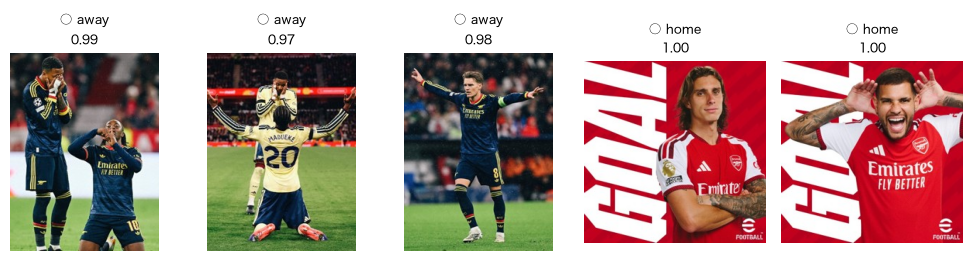

                                         写真    正解    予測    確率
0  31696B26-1EF0-48F9-9B54-C09D5CB4B1DE.jpg  away  away  0.99
1  5905F32B-516C-4E36-B7BA-95B083060558.jpg  away  away  0.97
2  FE1A3758-0D60-4CF7-B090-379F740E032B.jpg  away  away  0.98
3  90394397-E5AC-4383-A825-67726F9C3074.jpg  home  home  1.00
4  CC40B199-F21C-4F82-A53A-AA6FBB7EC745.jpg  home  home  1.00

自分のモデル：5 枚中 5 枚正解


In [7]:
from common import ASSETS
new_dir = ASSETS / "mynew"
if not new_dir.exists():
    from common.mydata import image_dir
    new_dir = image_dir()
    print("assets/mynew/ が無いので", new_dir, "から各クラス 5 枚を使う（学習に使った写真が混ざるので，正解数は高めに出る）")
photos = ImageFolder(root=str(new_dir))
if photos.classes != class_names:
    raise RuntimeError(f"新しい写真のフォルダ名 {photos.classes} が，学習したクラス {class_names} と違う")
picked = [i for k in range(len(class_names)) for i in [j for j, (_, y) in enumerate(photos.samples) if y == k][:5]]

tf = transforms.Compose([transforms.Resize((size, size)), transforms.ToTensor()])   # 演習1 の②（val）と同じ前処理
rows = []
fig, axes = plt.subplots(1, len(picked), figsize=(2 * len(picked), 2.6))
with torch.no_grad():                                   # 勾配を計算しない
    for ax, i in zip(axes, picked):
        image, label = photos[i]
        prob = torch.softmax(model(tf(image).unsqueeze(0).to(device)), dim=1)[0]   # 1 枚を (1, 3, 64, 64) にして流す
        pred = int(prob.argmax())
        rows.append({"写真": Path(photos.samples[i][0]).name, "正解": class_names[label],
                     "予測": class_names[pred], "確率": round(float(prob[pred]), 2)})
        ax.imshow(image); ax.axis("off")
        ax.set_title(f"{'○' if pred == label else '×'} {class_names[pred]}\n{float(prob[pred]):.2f}", fontsize=9)
plt.tight_layout(); plt.show()
result_df = pd.DataFrame(rows)
print(result_df.to_string())
my_correct = int((result_df["正解"] == result_df["予測"]).sum())
print(f"\n自分のモデル：{len(result_df)} 枚中 {my_correct} 枚正解")

## (6) LLM にも分類させる（討議のための実測）

ここでは LLM（ChatGPT・Gemini・Claude など）に写真を分類させる．

1. (5) と同じ写真を LLM に 1 枚ずつ渡し，次のように聞く．`A`・`B` は，クラスを **自分を知らない人に伝える言葉** で書く
   > この写真は「A」と「B」のどちらですか．A か B だけで答えてください．
2. 答えを，下のセルの `LLM_ANSWERS` に (5) の表の順にクラス名（フォルダ名）で書く

- 送るのは，顔・名前など個人が分かるものが写っていない写真だけ（送った写真は相手のサービスに残ることがある）

In [8]:
# ▼ (5) の表の順に，LLM の答えをクラス名で書く（例：["pen_mine", "pen_other", ...]）
LLM_ANSWERS = ["away", "away", "away", "home", "home"]

if len(LLM_ANSWERS) != len(result_df):
    raise RuntimeError(f"LLM の答えが {len(LLM_ANSWERS)} 個．(5) の表と同じ {len(result_df)} 個を書く")
if set(LLM_ANSWERS) - set(class_names):
    raise RuntimeError(f"クラス名は {class_names} のどれかで書く")
result_df["LLM"] = LLM_ANSWERS
llm_correct = int((result_df["正解"] == result_df["LLM"]).sum())
print(result_df.to_string())
print(f"\n新しい写真 {len(result_df)} 枚：自分のモデル {my_correct} 枚・LLM {llm_correct} 枚 正解")

from common.logger import ResultLogger
logger = ResultLogger(None, f"member{MEMBER_NO}", course="c1", day="d4", exercise="ex3", device=device)
logger.log_many({"my_correct": my_correct, "llm_correct": llm_correct, "n_photos": len(result_df)},
                condition=f"{new_dir.name}_{'_'.join(class_names)}", seed=0)
print("記録した:", logger.path.name)

                                         写真    正解    予測    確率   LLM
0  31696B26-1EF0-48F9-9B54-C09D5CB4B1DE.jpg  away  away  0.99  away
1  5905F32B-516C-4E36-B7BA-95B083060558.jpg  away  away  0.97  away
2  FE1A3758-0D60-4CF7-B090-379F740E032B.jpg  away  away  0.98  away
3  90394397-E5AC-4383-A825-67726F9C3074.jpg  home  home  1.00  home
4  CC40B199-F21C-4F82-A53A-AA6FBB7EC745.jpg  home  home  1.00  home

新しい写真 5 枚：自分のモデル 5 枚・LLM 5 枚 正解
記録した: c1_d4_ex3.csv


## ✋ 止まる 1：ここから先へは，グループ全員がそろってから進む

**問い**：メンバーのタスクのうち，専用モデルを作る価値があったのはどれか．LLM が当てられなかったタスクには，どんな共通点があるか

1. **presenter**（この演習の担当）：問いを読み上げ，話し合いを進める．全員の考えを聞き，根拠を含めて答えを 1〜2 文にまとめる
2. **全員**：自分のクラスと，(6) の自分のモデルと LLM の正解数を言う．根拠になる所：(6) の表で，LLM が外した写真．第3回 演習1 の5分類（1 アプリ開発 と 3-A 特化型）のどちらで作るべきか
3. 全員が下のセルの `CP1 = ""` に答えを書いて実行する（10 文字未満だと止まる）

In [9]:
# 問い：メンバーのタスクのうち，専用モデルを作る価値があったのはどれか．LLM が当てられなかったタスクには，どんな共通点があるか
# ▼ グループで決めた答えを " " の中に書く（1〜2 文）
CP1 = "メンバーのタスクのうちLLMよりも自分のモデルの方が正解率が高かったタスクはなかった。LLM が当てられなかったタスクは，すべて自分のモデルでも正解できなかった。"
checkpoint(CP1, "止まる 1")

止まる 1 OK：メンバーのタスクのうちLLMよりも自分のモデルの方が正解率が高かったタスクはなかった。LLM が当てられなかったタスクは，すべて自分のモデルでも正解できなかった。


## (7) 考察（提出）

このセルをダブルクリックして，＿＿ に書き込む（それぞれ 1〜2 文）．

1. 新しい写真での自分のモデルの正解数と，演習1 のテスト正解率を比べて分かること．外れた写真の特徴：＿＿
2. LLM の正解数．自分のタスクは，専用モデル（3-A）を作る価値があったか．その理由：＿＿
3. LLM では分類できない問題を 1 つ挙げ，それが必要な人・場面を書く：＿＿
4. 第3回 ex1.ipynb の振り返り 4「次につくってみたい AI」は，今日の方法で作れるか．5 分類のどれになるか：＿＿